In [6]:

%run parse_utils.ipynb

    
import json
import csv
import os
import matplotlib.pyplot as plt
import math

from collections import Counter
from collections import defaultdict

import pandas as pd
pd.options.mode.chained_assignment = None

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.anova import AnovaRM

from scikit_posthocs import posthoc_dunn
from scipy.stats import shapiro, levene, kruskal, kstest, norm

import numpy as np

ad_master_file = 'ad_master.csv'
db = pd.read_csv(ad_master_file)

In [7]:
lookup_file = 'exp_lookup_2025.csv'
lookup = pd.read_csv(lookup_file)
lookup['id'] = lookup['run_id'] + '_' + lookup['account']
    
drop_cols = ['pr1_count', 'pr2_count', 'preroll_ad_rate',
             'preroll_scam_rate', 'side_ad_rate', 'all_ad_rate', 'preroll_scam_count']
lookup = lookup.drop(drop_cols, axis=1)
lookup

,run_id,account,location,gender,video_set,video_count,watch_time,personalization_on,activity_on,pr_count,side_count,promoted_vid_count,run,id
0,1130_1400,tnkusa001,oregon-1,male,popular,400,30,True,True,67,11,104,1,1130_1400_tnkusa001
1,1130_1400,tnkusa002,oregon-1,male,popular,400,30,True,False,83,93,37,1,1130_1400_tnkusa002
2,1130_1400,tnkusa003,oregon-1,male,popular,400,30,False,False,76,87,38,1,1130_1400_tnkusa003
3,1106_1234,tnkusa004,oregon-2,male,conspiracy,400,30,True,True,60,133,6,1,1106_1234_tnkusa004
4,1106_1234,tnkusa005,oregon-2,male,conspiracy,400,30,True,False,94,222,20,1,1106_1234_tnkusa005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,0101_1600,tnkirl023,ireland-4,male,popular,400,30,True,False,42,42,7,6,0101_1600_tnkirl023
446,0101_1600,tnkirl024,ireland-4,male,popular,400,30,False,False,75,16,9,6,0101_1600_tnkirl024
447,0101_1600,tnkirl014,ireland-5,male,science,400,30,True,True,71,13,8,6,0101_1600_tnkirl014
448,0101_1600,tnkirl026,ireland-5,male,science,400,30,True,False,62,72,9,6,0101_1600_tnkirl026


In [8]:
# get a large df of every ads in a single folder/run
import time

folders = [f"output_run_{i}_2024" for i in range(1, 7)]
df_list = []
for folder in folders:
    for file in os.listdir(folder):
        if file.endswith('.json'):
            id = parse_id(file)
            if id in lookup['id'].tolist():
                df = parse_file(folder, id, no_ad_mode=False, verbose=False)
                df['id'] = [id]*len(df)
                df['country'] = df['id'].apply(to_country)
                df_list.append(df)
        
df = pd.concat(df_list)
df = pd.merge(df, lookup, on='id', how='outer')
df = df.dropna(subset=['video_id', 'run'])

df = melt_and_match_preroll(df)

df.replace('', np.nan, inplace=True)
df.loc[df['preroll_ad_reasons'].str.len() == 0, 'preroll_ad_reasons'] = None
df.replace(np.nan, None, inplace=True)
df["privacy_code"] = df['personalization_on'].astype(str) + '_' + df['activity_on'].astype(str)

ads = df[df['preroll_ad_id'].notnull()]

aus = df[df['country'] == 'aus']
can = df[df['country'] == 'can']
irl = df[df['country'] == 'irl']
usa = df[df['country'] == 'usa']
gbr = df[df['country'] == 'gbr']

df

,video_id,video_title,video_url,channel_name,video_genre,date_uploaded,likes,views,comment_count,has_more_than_two_ads,...,personalization_on,activity_on,pr_count,side_count,promoted_vid_count,run,preroll_ad_id,ad_order,preroll_is_scam,privacy_code
0,LmhOcdewJU4,Python py to exe 🏃,https://www.youtube.com/watch?v=LmhOcdewJU4,Bro Code,Science & Technology,2021-02-11T07:14:43-08:00,None,92415.0,120.0,False,...,True,True,57,34,20,6,cd5SZhHT-Wk,1.0,0,True_True
1,w8UI8r9Ccwk,8 Kitchen Gadgets put to the Test - Part 23,https://www.youtube.com/watch?v=w8UI8r9Ccwk,CrazyRussianHacker,Science & Technology,2018-03-04T14:34:38-08:00,None,1740142.0,1858.0,False,...,True,True,57,34,20,6,jfao1I96DCU,1.0,0,True_True
2,rHseRzVcQ4U,Aussie man turns bolt into bottle opener!,https://www.youtube.com/watch?v=rHseRzVcQ4U,I did a thing,Entertainment,2018-08-07T07:26:17-07:00,None,936936.0,1534.0,False,...,True,True,57,34,20,6,CdQCFZnlMdY,1.0,0,True_True
3,7VH9l4hgbII,Shooting Electrons In a Cloud Chamber Is Amazing!,https://www.youtube.com/watch?v=7VH9l4hgbII,The Action Lab,Science & Technology,2021-08-19T08:00:03-07:00,None,259342.0,661.0,False,...,True,True,57,34,20,6,oOMKmvJCBOA,1.0,1,True_True
4,0hXqHH7rZqo,How Did HP Fail This Hard? - HP Spectre x360 2...,https://www.youtube.com/watch?v=0hXqHH7rZqo,Linus Tech Tips,Science & Technology,2019-03-19T12:01:24-07:00,None,2250789.0,4316.0,False,...,True,True,57,34,20,6,TJ3pEFD5pes,1.0,0,True_True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194864,aEcAdduJRZU,Something Truly Unnatural is Going on...,https://www.youtube.com/watch?v=aEcAdduJRZU,Amplex,Entertainment,2018-06-27T10:00:09-07:00,None,235136.0,793.0,False,...,True,True,74,125,16,5,NaN,None,None,True_True
194865,wppsWC4EufU,Amazing Prophetic Parallels | Episode 939,https://www.youtube.com/watch?v=wppsWC4EufU,Perry Stone,Nonprofits & Activism,2018-10-05T07:41:44-07:00,None,61809.0,96.0,False,...,True,True,74,125,16,5,NaN,None,None,True_True
194866,fH-46i2RDBU,The Truth May Shock You! (2018-2019),https://www.youtube.com/watch?v=fH-46i2RDBU,Jason A,News & Politics,2018-11-24T17:07:26-08:00,None,398685.0,None,False,...,True,True,74,125,16,5,NaN,None,None,True_True
194867,I_0YqdL_TPs,Ancient Aliens: The Great Mayan Disappearance ...,https://www.youtube.com/watch?v=I_0YqdL_TPs,HISTORY,Entertainment,2019-07-20T15:00:01-07:00,None,1948734.0,2168.0,False,...,True,True,74,125,16,5,NaN,None,None,True_True


In [9]:
df.to_csv('all_video_2025.csv', index=False)

In [10]:
#  scam rates for gnerics

def scam_rate_for_generics(df):
    generics = ['The time of day or your general location (like your country or city)']
    gendf = df[df['preroll_ad_reasons_merged'].apply(lambda x: x == generics)]
    if gendf.empty:
        return 0.0
    scam_rate = (gendf['preroll_is_scam'].sum() / len(gendf))
    return scam_rate


def merge_generics(df):
    new_list = []
    
    generics = ['The time of day or your general location (like your country or city)',
     'The time of day', 'Your general location (like your country or city)',
     'La hora o tu ubicación general (por ejemplo, el país o la ciudad)',
     'A hora do dia ou sua localização geral (como o país ou a cidade)',
     'Günün saati veya genel konumunuz (bulunduğunuz ülke veya şehir gibi)',
     "L'heure de la journée ou votre situation géographique générale (par exemple, un pays ou une ville)",
     ]
    replacement = 'The time of day or your general location (like your country or city)'
    
    rm = []
    
    for reason_list in list(df['preroll_ad_reasons']):
        if not(reason_list):
            new_list.append(reason_list)
            continue

        reasons = [r for r in reason_list if r not in rm]
        reasons = [replacement if reason in generics else reason for reason in reasons]
        reasons = list(set(reasons))
        new_list.append(reasons)
        
    df['preroll_ad_reasons_merged'] = new_list
    return df

ads = df[df['preroll_ad_id'].notnull()]
ads = merge_generics(ads)
tt = ads[ads['privacy_code'] == 'True_True']
tf = ads[ads['privacy_code'] == 'True_False']
ff = ads[ads['privacy_code'] == 'False_False']
print(scam_rate_for_generics(tt))
print(scam_rate_for_generics(tf))
print(scam_rate_for_generics(ff))

0.06231454005934718
0.09664848012470771
0.0890416433538486


In [12]:
df = pd.read_csv('all_video_2025.csv', low_memory=False) 
ads = df[df['preroll_ad_id'].notnull()]
ads['occurences'] = ads.groupby('preroll_ad_id')['preroll_ad_id'].transform('count')
ads = ads.sort_values(by=['occurences'], ascending=False)
unique_ads = ads.drop_duplicates(subset=['preroll_ad_id']).reset_index(drop=True)
all_scams = unique_ads[unique_ads['preroll_is_scam'] == 1]

pr = sum(unique_ads['occurences'])
pr_u = len(unique_ads)
pr_scam = sum(all_scams['occurences'])
pr_scam_u = len(all_scams)
# side = df['side_ad_img'].count()
# promo = df['promoted_video_url'].count()
# total_impressions = pr + side + promo

print(f"total preroll impressions: {sum(unique_ads['occurences'])}")
print(f"total unique preroll impressions: {len(unique_ads)}")
print(f"total scam impressions: {sum(all_scams['occurences'])}")
print(f"total unique scam impressions: {len(all_scams)}")
# print(f"total side ad impressions: {df['side_ad_img'].count()}")
# print(f"total promoted vid impressions: {df['promoted_video_url'].count()}")
# print(f"total ad impressions: {total_impressions}")
# print(f"\\textbf{{Total}} & {pr} ({pr_u}) & {pr_scam} ({pr_scam_u}) & {side} & {promo} \\\\")
print()

impression_list, unique_list, scamimpression_list, scamunique_list = [], [], [], []

for run in range(1,7):
    rundf = df[df['run'] == run]
    ads_run = rundf[rundf['preroll_ad_id'].notnull()]
    ads_run['occurences'] = ads_run.groupby('preroll_ad_id')['preroll_ad_id'].transform('count')
    ads_run.sort_values(by=['occurences'], ascending=False)
    unique_ads_by_run = ads_run.drop_duplicates(subset=['preroll_ad_id']).reset_index(drop=True)
    scam_run = unique_ads_by_run[unique_ads_by_run['preroll_is_scam'] == 1]
    
    pr = sum(unique_ads_by_run['occurences'])
    pr_u = len(unique_ads_by_run)
    pr_scam = sum(scam_run['occurences'])
    pr_scam_u = len(scam_run)
#     side = rundf['side_ad_img'].count()
#     promo = rundf['promoted_video_url'].count()

    impression_list.append(len(ads_run))
    unique_list.append(pr_u)
    scamimpression_list.append(pr_scam)
    scamunique_list.append(pr_scam_u)

    print(f"Run {run} preroll impressions: {len(ads_run)}")
    print(f"Run {run} unique preroll impressions: {pr_u}")
    print(f"Run {run} preroll scam impressions: {pr_scam}")
    print(f"Run {run} preroll unique scam impressions: {pr_scam_u}")
#     print(f"Run {run} side ad impressions: {side}")
#     print(f"Run {run} promoted vid impressions: {promo}")
    print()
    
#     print(f"\\textbf{{Run {run}}} & {pr} ({pr_u}) & {pr_scam} ({pr_scam_u}) & {side} & {promo} \\\\")
print('validation')
#  Unique ads (in parentheses) do not add up to the total because ads can re-appear across runs.
print(f"total preroll impressions: {sum(impression_list)}")
print(f"total unique preroll impressions: {sum(unique_list)}")
print(f"total scam impressions: {sum(scamimpression_list)}")
print(f"total unique scam impressions: {sum(scamunique_list)}")

total preroll impressions: 34595
total unique preroll impressions: 9199
total scam impressions: 2463
total unique scam impressions: 545

Run 1 preroll impressions: 5578
Run 1 unique preroll impressions: 2669
Run 1 preroll scam impressions: 307
Run 1 preroll unique scam impressions: 137

Run 2 preroll impressions: 5818
Run 2 unique preroll impressions: 2259
Run 2 preroll scam impressions: 433
Run 2 preroll unique scam impressions: 152

Run 3 preroll impressions: 5748
Run 3 unique preroll impressions: 2246
Run 3 preroll scam impressions: 372
Run 3 preroll unique scam impressions: 126

Run 4 preroll impressions: 5717
Run 4 unique preroll impressions: 2339
Run 4 preroll scam impressions: 355
Run 4 preroll unique scam impressions: 113

Run 5 preroll impressions: 5879
Run 5 unique preroll impressions: 2204
Run 5 preroll scam impressions: 497
Run 5 preroll unique scam impressions: 156

Run 6 preroll impressions: 5855
Run 6 unique preroll impressions: 2323
Run 6 preroll scam impressions: 499
R

In [13]:
# The top 10~predatory ads by impression counts
all_scams = all_scams.sort_values(by=['occurences'], ascending=False).reset_index(drop=True)
print(sum(all_scams.iloc[:10]['occurences'])/sum(all_scams['occurences']))
print(sum(all_scams.iloc[:10]['occurences'])/sum(unique_ads['occurences']))

0.2866423061307349
0.02040757334874982


In [14]:
all_id_dict = {}
for run in range(1,7):
    rundf = lookup[lookup['run']==run]
    all_id_dict[run] = rundf['id'].tolist()
    
# all_id_dict

In [15]:
run_dfs = []
VIDEO_COUNT = 400

for run in range(1, 7):
    pr1_count, pr2_count, pr_count = [], [], []
    pr1_scam_count, pr2_scam_count, pr_scam_count = [], [], []
    pr1_scam_rates, pr2_scam_rates, pr_scam_rates = [], [], []

    for run_id in all_id_dict[run]:
        
        rundf = ads[ads["id"]==run_id]

        pr1 = rundf[rundf["ad_order"]==1]
        pr2 = rundf[rundf["ad_order"]==2]
        pr1_scam = pr1[pr1["preroll_is_scam"]==1]
        pr2_scam = pr2[pr2["preroll_is_scam"]==1]
        pr_scam = rundf[rundf["preroll_is_scam"]==1]
        assert(len(pr_scam) == len(pr1_scam)+len(pr2_scam))
        pr1_scam_rate = len(pr1_scam)/len(pr1)
        pr2_scam_rate = len(pr2_scam)/len(pr2)
        pr_scam_rate = len(pr_scam) / len(rundf)

        pr1_count.append(len(pr1))
        pr2_count.append(len(pr2))
        pr_count.append(len(rundf))

        pr1_scam_count.append(len(pr1_scam))
        pr2_scam_count.append(len(pr2_scam))
        pr_scam_count.append(len(pr_scam))

        pr1_scam_rates.append(pr1_scam_rate)
        pr2_scam_rates.append(pr2_scam_rate)
        pr_scam_rates.append(pr_scam_rate)

    # generate results df
    cols = ["run", "id", "pr1_count", "pr2_count", "pr_count", "pr_ad_load",
            "pr1_scam_count", "pr2_scam_count", "pr_scam_count",
            "pr1_scam_rate", "pr2_scam_rate", "pr_scam_rate"]

    data = [[run]*len(all_id_dict[run]), all_id_dict[run], pr1_count, pr2_count, pr_count, [i/VIDEO_COUNT for i in pr_count],
            pr1_scam_count, pr2_scam_count, pr_scam_count,
            pr1_scam_rates, pr2_scam_rates, pr_scam_rates]

    data_transposed = list(map(list, zip(*data)))

    run_df = pd.DataFrame(data_transposed, columns=cols)
    run_dfs.append(run_df)
    
iddf = pd.concat(run_dfs, ignore_index=True)
iddf.reset_index(inplace=True, drop=True)
display(iddf)

,run,id,pr1_count,pr2_count,pr_count,pr_ad_load,pr1_scam_count,pr2_scam_count,pr_scam_count,pr1_scam_rate,pr2_scam_rate,pr_scam_rate
0,1,1130_1400_tnkusa001,41,26,67,0.1675,0,0,0,0.000000,0.000000,0.000000
1,1,1130_1400_tnkusa002,53,30,83,0.2075,0,0,0,0.000000,0.000000,0.000000
2,1,1130_1400_tnkusa003,52,24,76,0.1900,1,0,1,0.019231,0.000000,0.013158
3,1,1106_1234_tnkusa004,32,28,60,0.1500,0,0,0,0.000000,0.000000,0.000000
4,1,1106_1234_tnkusa005,47,47,94,0.2350,7,10,17,0.148936,0.212766,0.180851
...,...,...,...,...,...,...,...,...,...,...,...,...
445,6,0101_1600_tnkirl023,32,10,42,0.1050,0,0,0,0.000000,0.000000,0.000000
446,6,0101_1600_tnkirl024,51,24,75,0.1875,2,0,2,0.039216,0.000000,0.026667
447,6,0101_1600_tnkirl014,39,32,71,0.1775,0,0,0,0.000000,0.000000,0.000000
448,6,0101_1600_tnkirl026,41,21,62,0.1550,0,0,0,0.000000,0.000000,0.000000


In [16]:
# add in more columns like personalization on, activity on etc. from lookup df
cols_to_use = iddf.columns.difference(lookup.columns)
iddf = pd.merge(lookup, iddf[cols_to_use], left_index=True, right_index=True, how='outer')

VIDEO_COUNT = 400

iddf["side_pv_count"] = iddf["side_count"] + iddf["promoted_vid_count"]
iddf["side_pv_load"] = iddf["side_pv_count"]/VIDEO_COUNT
iddf['all_ad_count'] = iddf["side_count"] + iddf["promoted_vid_count"] + iddf["pr_count"]
iddf["all_ad_rate"] = iddf['all_ad_count']/VIDEO_COUNT
iddf["predatory_load"] = iddf["pr_scam_count"]/VIDEO_COUNT
iddf['country'] = iddf['account'].apply(to_country)
iddf["inflated_pr_scam_count"] = iddf["pr_scam_count"].apply(lambda x: x+0.5 if x==0 else x)
iddf["inflated_pr_scam_rate"] = iddf["inflated_pr_scam_count"]/iddf["pr_count"]
iddf["privacy_code"] = iddf['personalization_on'].astype(str) + '_' + iddf['activity_on'].astype(str)

print(iddf.columns)
iddf.to_csv('results_2025.csv', index=False)
iddf

Index(['run_id', 'account', 'location', 'gender', 'video_set', 'video_count',
       'watch_time', 'personalization_on', 'activity_on', 'pr_count',
       'side_count', 'promoted_vid_count', 'run', 'id', 'pr1_count',
       'pr1_scam_count', 'pr1_scam_rate', 'pr2_count', 'pr2_scam_count',
       'pr2_scam_rate', 'pr_ad_load', 'pr_scam_count', 'pr_scam_rate',
       'side_pv_count', 'side_pv_load', 'all_ad_count', 'all_ad_rate',
       'predatory_load', 'country', 'inflated_pr_scam_count',
       'inflated_pr_scam_rate', 'privacy_code'],
      dtype='str')


,run_id,account,location,gender,video_set,video_count,watch_time,personalization_on,activity_on,pr_count,...,pr_scam_rate,side_pv_count,side_pv_load,all_ad_count,all_ad_rate,predatory_load,country,inflated_pr_scam_count,inflated_pr_scam_rate,privacy_code
0,1130_1400,tnkusa001,oregon-1,male,popular,400,30,True,True,67,...,0.000000,115,0.2875,182,0.4550,0.0000,usa,0.5,0.007463,True_True
1,1130_1400,tnkusa002,oregon-1,male,popular,400,30,True,False,83,...,0.000000,130,0.3250,213,0.5325,0.0000,usa,0.5,0.006024,True_False
2,1130_1400,tnkusa003,oregon-1,male,popular,400,30,False,False,76,...,0.013158,125,0.3125,201,0.5025,0.0025,usa,1.0,0.013158,False_False
3,1106_1234,tnkusa004,oregon-2,male,conspiracy,400,30,True,True,60,...,0.000000,139,0.3475,199,0.4975,0.0000,usa,0.5,0.008333,True_True
4,1106_1234,tnkusa005,oregon-2,male,conspiracy,400,30,True,False,94,...,0.180851,242,0.6050,336,0.8400,0.0425,usa,17.0,0.180851,True_False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,0101_1600,tnkirl023,ireland-4,male,popular,400,30,True,False,42,...,0.000000,49,0.1225,91,0.2275,0.0000,irl,0.5,0.011905,True_False
446,0101_1600,tnkirl024,ireland-4,male,popular,400,30,False,False,75,...,0.026667,25,0.0625,100,0.2500,0.0050,irl,2.0,0.026667,False_False
447,0101_1600,tnkirl014,ireland-5,male,science,400,30,True,True,71,...,0.000000,21,0.0525,92,0.2300,0.0000,irl,0.5,0.007042,True_True
448,0101_1600,tnkirl026,ireland-5,male,science,400,30,True,False,62,...,0.000000,81,0.2025,143,0.3575,0.0000,irl,0.5,0.008065,True_False


In [17]:
def output_diff(vdf, metric):
    tt = vdf[(vdf["personalization_on"]==True)&(vdf["activity_on"]==True)]
    tf = vdf[(vdf["personalization_on"]==True)&(vdf["activity_on"]==False)]
    ff = vdf[(vdf["personalization_on"]==False)&(vdf["activity_on"]==False)]

    ttl = np.array(tt[metric])
    tfl = np.array(tf[metric])
    ffl = np.array(ff[metric])

    test = pd.DataFrame({
        "tt":ttl,
        "tf":tfl,
        "ff":ffl
    })

#     indices = np.where(ttl==0)
    indices = []
    ttl = np.delete(ttl, indices)
    tfl = np.delete(tfl, indices)
    ffl = np.delete(ffl, indices)

    tf_diff = np.mean(tfl)/np.mean(ttl)
    ff_diff = np.mean(ffl)/np.mean(ttl)
    
    tf_mean = f"{tf_diff:.2f}"
    ff_mean = f"{ff_diff:.2f}"
    
    print(f'{tf_mean} & {ff_mean} & {len(ttl)} \\\\')


# metric = "pr_ad_load"
metric = "pr_scam_rate"

print('overall')
vdf = iddf
output_diff(vdf, metric)

print('video')
vsets = ["news", "popular", "science", "conspiracy", "kids"]
for video_set in vsets:
    vdf = iddf[iddf["video_set"]==video_set]
    output_diff(vdf, metric)
    
print('country') 
locs = ["aus", "can", "irl", "usa", "gbr"]
for loc in locs:
    vdf = iddf[iddf["country"]==loc]
    output_diff(vdf, metric)




overall
3.42 & 3.46 & 150 \\
video
2.94 & 2.89 & 30 \\
4.19 & 3.08 & 30 \\
3.11 & 2.68 & 30 \\
4.21 & 4.62 & 30 \\
1.19 & 1.20 & 30 \\
country
6.81 & 6.22 & 30 \\
1.75 & 2.18 & 30 \\
2.56 & 3.10 & 30 \\
4.64 & 3.62 & 30 \\
3.58 & 4.02 & 30 \\


In [18]:
stats = tt['preroll_is_scam'].agg(['mean', 'min', 'max', 'std'])
print(stats)

mean    0.02518
min     0.00000
max     1.00000
std     0.15668
Name: preroll_is_scam, dtype: float64


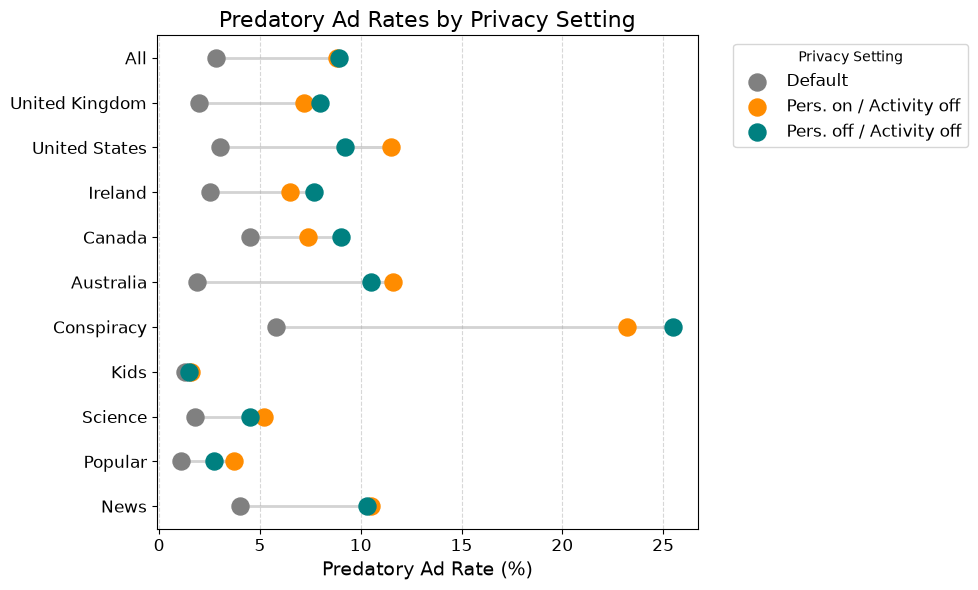

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Category': ['News', 'Popular', 'Science', 'Kids', 'Conspiracy',
                 'Australia', 'Canada', 'Ireland', 'United States', 'United Kingdom', 'All'],
    'Default': [4.0, 1.1, 1.8, 1.3, 5.8, 1.9, 4.5, 2.5, 3.0, 2.0, 2.8],
    'Pers. on / Activity off': [10.5, 3.7, 5.2, 1.6, 23.2, 11.6, 7.4, 6.5, 11.5, 7.2, 8.8],
    'Pers. off / Activity off': [10.3, 2.7, 4.5, 1.5, 25.5, 10.5, 9.0, 7.7, 9.2, 8.0, 8.9]
}
df_full = pd.DataFrame(data)

full_color_map = {
    'Default': 'gray',
    'Pers. on / Activity off': 'darkorange',
    'Pers. off / Activity off': 'teal'
}
settings_order = ['Default', 'Pers. on / Activity off', 'Pers. off / Activity off']

plt.figure(figsize=(10, 6))
for i, category in enumerate(df_full['Category']):
    x_vals = [df_full.loc[i, setting] for setting in settings_order]
    plt.plot(x_vals, [i, i, i], color='lightgray', linewidth=2, zorder=1)
    for j, setting in enumerate(settings_order):
        plt.scatter(x_vals[j], i, color=full_color_map[setting], s=150, zorder=2,
                    marker='o', label=setting if i == 0 else "")

plt.yticks(range(len(df_full['Category'])), df_full['Category'], fontsize=12)
plt.xticks(fontsize=12)
plt.xlabel('Predatory Ad Rate (%)', fontsize=14)
plt.ylabel('')
plt.title('Predatory Ad Rates by Privacy Setting', fontsize=16)
plt.legend(title='Privacy Setting', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [24]:
import pandas as pd

df = pd.read_csv("results_2025.csv")

df['Privacy Setting'] = df['privacy_code'].map({
    'True_True': 'Default',
    'True_False': 'Pers. on / Activity off',
    'False_False': 'Pers. off / Activity off'
})

video_set_df = df.rename(columns={
    'video_set': 'Category',
    'pr_scam_rate': 'Predatory Ad Rate'
})[['Category', 'Privacy Setting', 'Predatory Ad Rate']]

country_df = df.rename(columns={
    'country': 'Category',
    'pr_scam_rate': 'Predatory Ad Rate'
})[['Category', 'Privacy Setting', 'Predatory Ad Rate']]

df_all = df.copy()
df_all['Category'] = 'All'
df_all = df_all.rename(columns={'pr_scam_rate': 'Predatory Ad Rate'})[['Category', 'Privacy Setting', 'Predatory Ad Rate']]

df_real = pd.concat([df_all, country_df, video_set_df], ignore_index=True)
df_real

,Category,Privacy Setting,Predatory Ad Rate
0,All,Default,0.000000
1,All,Pers. on / Activity off,0.000000
2,All,Pers. off / Activity off,0.013158
3,All,Default,0.000000
4,All,Pers. on / Activity off,0.180851
...,...,...,...
1345,popular,Pers. on / Activity off,0.000000
1346,popular,Pers. off / Activity off,0.026667
1347,science,Default,0.000000
1348,science,Pers. on / Activity off,0.000000


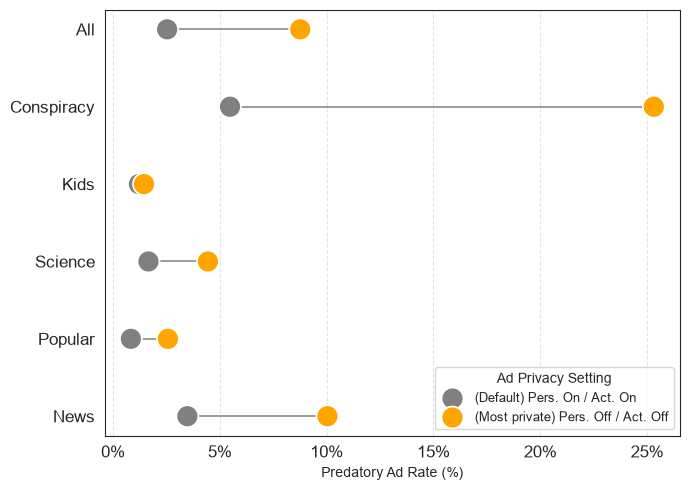

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

category_mapping = {
    'usa': 'United States',
    'gbr': 'United Kingdom',
    'irl': 'Ireland',
    'can': 'Canada',
    'aus': 'Australia',
    'news': 'News',
    'popular': 'Popular',
    'science': 'Science',
    'kids': 'Kids',
    'conspiracy': 'Conspiracy',
    'all': 'All'
}
df_real['Category'] = df_real['Category'].str.strip().str.lower().map(category_mapping).fillna(df_real['Category'])

plot_order = [
    'All',
#     'United Kingdom', 'United States', 'Ireland', 'Canada', 'Australia',
    'Conspiracy', 'Kids', 'Science', 'Popular', 'News'
]

grouped = df_real.groupby(['Category', 'Privacy Setting'])['Predatory Ad Rate'].mean().reset_index()
grouped = grouped[grouped['Privacy Setting'] != "Pers. on / Activity off"]
pivot = grouped.pivot(index='Category', columns='Privacy Setting', values='Predatory Ad Rate').reset_index()

category_positions = {cat: i for i, cat in enumerate(plot_order[::-1])}
grouped['y'] = grouped['Category'].map(category_positions)

plt.figure(figsize=(7,5))
sns.set_style("white")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.grid(axis='y', which='both', linestyle='', alpha=0)  # turn off horizontal grid lines

# Horizontal lines connecting the min and max within each category
for i, row in pivot.iterrows():
    values = row[1:].dropna().values
    if len(values) >= 2 and row['Category'] in category_positions:
        y = category_positions[row['Category']]
        plt.plot([min(values)*100, max(values)*100], [y, y], color='gray',
                 linewidth=1.1, zorder=1)

# Scatter plot
ax = sns.scatterplot(
    data=grouped,
    x=grouped['Predatory Ad Rate'] * 100,
    y='y',
    hue='Privacy Setting',
    palette={
        'Default': 'gray',
        'Pers. off / Activity off': 'orange' 
    },
    s=250,
    zorder=2
)

FONTSIZE = 12
handles, labels = ax.get_legend_handles_labels()
settings_order = ['Default', 'Pers. off / Activity off']
ordered_handles = [handles[labels.index(s)] for s in settings_order]
ax.legend(
    ordered_handles,
    ['(Default) Pers. On / Act. On', '(Most private) Pers. Off / Act. Off'],
    title='Ad Privacy Setting',
    loc='lower right',
    bbox_to_anchor=(1, 0),
    fontsize=FONTSIZE-3,
    title_fontsize=FONTSIZE-2,
    frameon=True
)

# Format y-axis with category names
plt.yticks(ticks=list(category_positions.values()), labels=list(category_positions.keys()))
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.xticks(fontsize=FONTSIZE)
plt.yticks(fontsize=FONTSIZE)
# plt.title('Predatory Ad Rates by Privacy Setting', fontsize=FONTSIZE+2)
plt.xlabel('Predatory Ad Rate (%)')
plt.ylabel('')
# plt.legend(title='Privacy Setting', loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


In [83]:
df_real

,Category,Privacy Setting,Predatory Ad Rate
0,All,Default,0.000000
1,All,Pers. on / Activity off,0.000000
2,All,Pers. off / Activity off,0.013158
3,All,Default,0.000000
4,All,Pers. on / Activity off,0.180851
...,...,...,...
1345,Popular,Pers. on / Activity off,0.000000
1346,Popular,Pers. off / Activity off,0.026667
1347,Science,Default,0.000000
1348,Science,Pers. on / Activity off,0.000000


In [38]:
agg

,Category,Privacy Setting,mean,std,base_y,y
0,All,Default,0.025309,0.030591,12,12.00
1,All,Pers. off / Activity off,0.087617,0.106167,12,11.75
2,All,Pers. on / Activity off,0.086666,0.103163,12,12.25
3,Australia,Default,0.016865,0.021084,6,6.00
4,Australia,Pers. off / Activity off,0.104906,0.133244,6,5.75
5,Australia,Pers. on / Activity off,0.114845,0.143686,6,6.25
6,Canada,Default,0.040711,0.034349,7,7.00
7,Canada,Pers. off / Activity off,0.088602,0.108505,7,6.75
8,Canada,Pers. on / Activity off,0.071057,0.078431,7,7.25
9,Conspiracy,Default,0.054752,0.033039,4,4.00


['xx', 'xx', 'xx', 'xx', 'xx', 'xx', 'xx', 'xx', 'xx', 'xx', 'xx', '', '', '', '', '', '', '', '', '', '', '', '/', '/', '/', '/', '/', '/', '/', '/', '/', '/', '/']


/var/folders/jm/1_69h8ts1hqb42r2llvj363c0000gn/T/ipykernel_81658/1213700940.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([


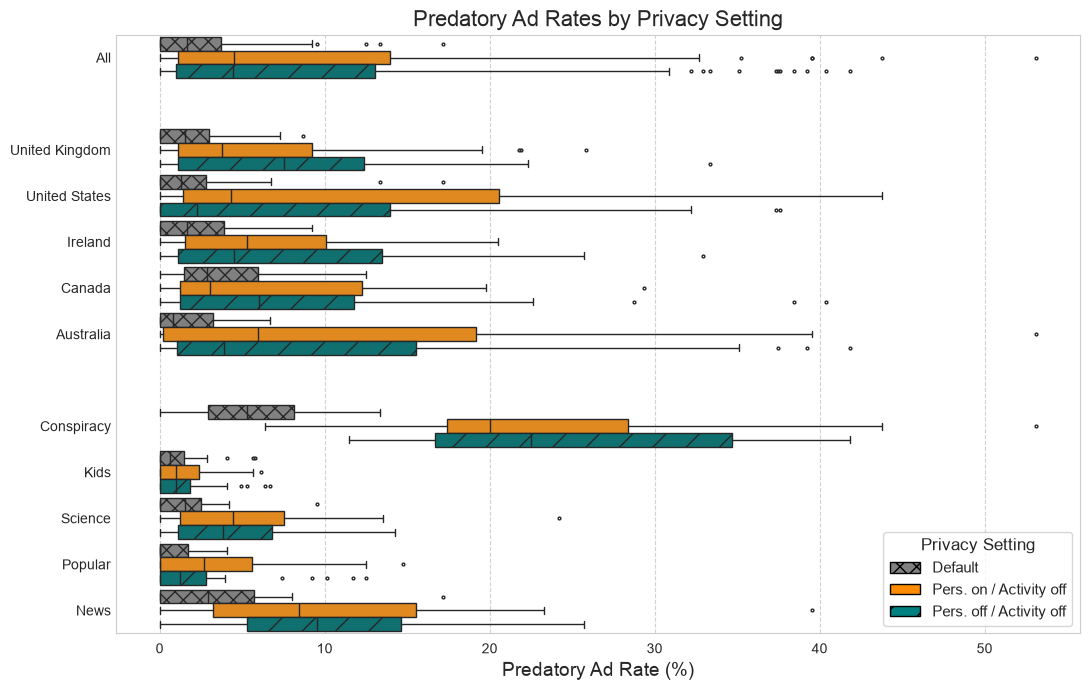

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

category_mapping = {
    'usa': 'United States',
    'gbr': 'United Kingdom',
    'irl': 'Ireland',
    'can': 'Canada',
    'aus': 'Australia',
    'news': 'News',
    'popular': 'Popular',
    'science': 'Science',
    'kids': 'Kids',
    'conspiracy': 'Conspiracy',
    'All': 'All'
}
df_real['Category'] = df_real['Category'].str.strip().str.lower().map(category_mapping).fillna(df_real['Category'])

# Ordering
spaced_order = [
    'All', '<gap1>',
    'United Kingdom', 'United States', 'Ireland', 'Canada',
    'Australia', '<gap2>',
    'Conspiracy', 'Kids', 'Science', 'Popular', 'News'
]
settings_order = ['Default', 'Pers. on / Activity off', 'Pers. off / Activity off']

full_color_map = {
    'Default': 'gray',
    'Pers. on / Activity off': 'darkorange',
    'Pers. off / Activity off': 'teal'
}

# Add dummy rows for gaps 
gap_rows = []
for gap in ['<gap1>', '<gap2>']:
    for setting in settings_order:
        gap_rows.append({
            'Category': gap,
            'Privacy Setting': setting,
            'Predatory Ad Rate': np.nan
        })
df_full = pd.concat([df_real, pd.DataFrame(gap_rows)], ignore_index=True)

plt.figure(figsize=(11, 7))
sns.set_style("whitegrid")

ax = sns.boxplot(
    data=df_full,
    x='Predatory Ad Rate',
    y='Category',
    hue='Privacy Setting',
    order=spaced_order,
    palette=full_color_map,
    fliersize=2,
    width=0.9
)

# Format x-axis as %
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}'))

# Hide y-tick labels for gap rows
ax.set_yticklabels([
    '' if 'gap' in label else label for label in spaced_order
])

import matplotlib.patches as mpatches

# Manually assign hatches to each patch by index 
hatch_pattern = ['xx', '', '/']
manual_hatches = sum([[h] * 11 for h in hatch_pattern], [])
print(manual_hatches)

for patch, hatch in zip(ax.patches, manual_hatches):
    patch.set_hatch(hatch)
    
# Custom legend handles with hatching
handles = [
    mpatches.Patch(
        facecolor=full_color_map[setting],
        hatch=hatch_pattern[i],
        edgecolor='black',
        label=setting
    )
    for i, setting in enumerate(settings_order)
]


ax.legend(handles=handles, title='Privacy Setting',
          loc='lower right', fontsize=11, title_fontsize=12, frameon=True)

# Final formatting
plt.grid(True, axis='x', linestyle='--', alpha=0.9)
plt.xlabel('Predatory Ad Rate (%)', fontsize=14)
plt.ylabel('')
plt.tick_params(axis='y', length=0)
plt.title('Predatory Ad Rates by Privacy Setting', fontsize=16)
plt.tight_layout()
plt.show()


In [34]:
# create raw tables for the appendix

vsets = ["news", "popular", "science", "conspiracy", "kids"] 
locs = ["aus", "can", "irl", "usa", "gbr"]

video_set = vsets[4]
print(video_set)

vdf = iddf[iddf["video_set"]==video_set]

tt = vdf[(vdf["personalization_on"]==True)&(vdf["activity_on"]==True)]
tf = vdf[(vdf["personalization_on"]==True)&(vdf["activity_on"]==False)]
ff = vdf[(vdf["personalization_on"]==False)&(vdf["activity_on"]==False)]

for loc in locs:
    for run in range(1, 7):
        #there should only be one row
        ttrow = tt[(tt["country"]==loc) & (tt["run"]==run)]
        tt_prcount = int(ttrow['pr_count'].iloc[0])
        tt_scamrate = round(float(ttrow['pr_scam_rate'].iloc[0]), 4)
        
        tfrow = tf[(tf["country"]==loc) & (tf["run"]==run)]
        tf_prcount = int(tfrow['pr_count'].iloc[0])
        tf_scamrate = round(float(tfrow['pr_scam_rate'].iloc[0]), 4)
        
        ffrow = ff[(ff["country"]==loc) & (ff["run"]==run)]
        ff_prcount = int(ffrow['pr_count'].iloc[0])
        ff_scamrate = round(float(ffrow['pr_scam_rate'].iloc[0]), 4)
        
        print(f"{tt_prcount}  {tt_scamrate:.4f}  {tf_prcount}  {tf_scamrate:.4f}  {ff_prcount}  {ff_scamrate:.4f}")

kids
76  0.0000  104  0.0000  110  0.0182
79  0.0000  96  0.0104  97  0.0103
81  0.0000  65  0.0000  109  0.0000
78  0.0000  108  0.0000  109  0.0000
80  0.0000  115  0.0087  108  0.0000
82  0.0000  76  0.0132  85  0.0000
76  0.0132  98  0.0000  97  0.0000
74  0.0270  96  0.0000  89  0.0112
71  0.0563  86  0.0116  108  0.0185
67  0.0149  103  0.0000  48  0.0208
72  0.0278  88  0.0568  106  0.0094
74  0.0000  88  0.0227  91  0.0000
70  0.0286  86  0.0233  57  0.0526
72  0.0000  98  0.0612  96  0.0000
73  0.0411  96  0.0312  90  0.0667
74  0.0135  84  0.0532  98  0.0408
69  0.0580  82  0.0244  78  0.0641
104  0.0192  84  0.0119  97  0.0103
74  0.0000  108  0.0000  110  0.0000
80  0.0125  112  0.0268  112  0.0000
74  0.0135  106  0.0000  113  0.0000
80  0.0000  113  0.0000  113  0.0000
76  0.0132  116  0.0000  123  0.0325
91  0.0000  115  0.0000  108  0.0000
78  0.0000  97  0.0103  102  0.0098
71  0.0000  104  0.0096  99  0.0101
82  0.0122  112  0.0268  109  0.0000
78  0.0000  100  0.0000

In [35]:
aus = iddf[iddf['country'] == 'aus']
can = iddf[iddf['country'] == 'can']
irl = iddf[iddf['country'] == 'irl']
usa = iddf[iddf['country'] == 'usa']
gbr = iddf[iddf['country'] == 'gbr']


popular = iddf[iddf['video_set'] == 'popular']
kids =  iddf[iddf['video_set'] == 'kids']
news =  iddf[iddf['video_set'] == 'news']
science =  iddf[iddf['video_set'] == 'science']
conspiracy =  iddf[iddf['video_set'] == 'conspiracy']

dft = iddf
# dft = iddf[(iddf['run']==1) | (iddf['run']==6)]
# dft = iddf[iddf['country'] != 'aus']
# dft = iddf[(iddf['country'] == 'usa') | (iddf['country'] == 'can')]
# dft = iddf[(iddf['country'] == 'usa')]
# dft = conspiracy

# metric = "pr_ad_load"
# metric = "pr_count"
metric = "pr_scam_rate"
# metric = "pr_scam_count"
# metric = "inflated_pr_scam_rate"
# metric = "all_ad_rate"
# metric = "all_ad_count"
# metric = "side_pv_load"
# metric = "side_pv_count"
# metric = "predatory_load"

tt = dft[(dft["personalization_on"]==True)&(dft["activity_on"]==True)]
tf = dft[(dft["personalization_on"]==True)&(dft["activity_on"]==False)]
ff = dft[(dft["personalization_on"]==False)&(dft["activity_on"]==False)]


ttl = list(tt[metric])
tfl = list(tf[metric])
ffl = list(ff[metric])

test = pd.DataFrame({
    "tt":ttl,
    "tf":tfl,
    "ff":ffl
})
test = pd.melt(test.reset_index(), id_vars=['index'], value_vars=["tt","tf","ff"])
test.columns = ['index', 'privacy', 'rate']

display(test)

# test['rate'].value_counts()


,index,privacy,rate
0,0,tt,0.000000
1,1,tt,0.000000
2,2,tt,0.000000
3,3,tt,0.000000
4,4,tt,0.000000
...,...,...,...
445,145,ff,0.137931
446,146,ff,0.000000
447,147,ff,0.010309
448,148,ff,0.026667


In [36]:
# multiple friedman test and conover posthoc
import pandas as pd
from scipy.stats import friedmanchisquare
from statsmodels.stats.multitest import multipletests
import scikit_posthocs as sp

df = iddf
metric = "pr_scam_rate"

p_values = [] 
labels = []
pairwise_p_values = [] 
pairwise_labels = []    
friedman_results = []

# Overall Friedman test
data = [df[df['privacy_code'] == p][metric].values for p in df['privacy_code'].unique()]
stat, p = friedmanchisquare(*data)
p_values.append(p)
labels.append("overall")
friedman_results.append({"Subset": "Overall",
                         "Friedman Stat": stat,
                         "Original p-value": p})

conover_results = sp.posthoc_conover(df, val_col=metric, group_col='privacy_code', p_adjust='holm')
for col in conover_results.columns:
    for row in conover_results.index:
        if row < col:  
            pairwise_p_values.append(conover_results.loc[row, col])
            pairwise_labels.append(f"Overall: {row} vs {col}")
                
# friedman test for country and video set
for country in df['country'].unique():
    subset = df[df['country'] == country]
    data = [subset[subset['privacy_code'] == p][metric].values for p in subset['privacy_code'].unique()]
    stat, p = friedmanchisquare(*data)
    p_values.append(p)
    labels.append(f"Country {country}")
    friedman_results.append({"Subset": f"Country {country}",
                             "Friedman Stat": stat,
                             "Original p-value": p})
    
    conover_results = sp.posthoc_conover(subset, val_col=metric,
                                         group_col='privacy_code', p_adjust=None)
    for col in conover_results.columns:
        for row in conover_results.index:
            if row < col:
                pairwise_p_values.append(conover_results.loc[row, col])
                pairwise_labels.append(f"Country {country}: {row} vs {col}")
                
for video_set in df['video_set'].unique():
    subset = df[df['video_set'] == video_set]
    data = [subset[subset['privacy_code'] == p][metric].values for p in subset['privacy_code'].unique()]
    stat, p = friedmanchisquare(*data)
    p_values.append(p)
    labels.append(f"Video Set {video_set}")
    friedman_results.append({"Subset": f"Video Set {video_set}",
                             "Friedman Stat": stat,
                             "Original p-value": p})
    
    conover_results = sp.posthoc_conover(subset, val_col=metric,
                                         group_col='privacy_code', p_adjust=None)
    for col in conover_results.columns:
        for row in conover_results.index:
            if row < col:
                pairwise_p_values.append(conover_results.loc[row, col])
                pairwise_labels.append(f"Video set {video_set}: {row} vs {col}")
                

p_correction_method = 'holm'
_, p_corrected, _, _ = multipletests(p_values, method=p_correction_method)
_, pairwise_p_corrected, _, _ = multipletests(pairwise_p_values, method=p_correction_method)

for i, corrected_p in enumerate(p_corrected):
    friedman_results[i][f"Corrected p-value"] = corrected_p
    
friedman_df = pd.DataFrame(friedman_results)
pairwise_df = pd.DataFrame({
    "Comparison": pairwise_labels,
    "Original p-value": pairwise_p_values,
    "Corrected p-value": pairwise_p_corrected
})

friedman_df['Original p-value'] = friedman_df['Original p-value'].map('{:.6f}'.format)
friedman_df['Corrected p-value'] = friedman_df['Corrected p-value'].map('{:.6f}'.format)

pairwise_df['Original p-value'] = pairwise_df['Original p-value'].map('{:.6f}'.format)
pairwise_df['Corrected p-value'] = pairwise_df['Corrected p-value'].map('{:.6f}'.format)

display(friedman_df)
display(pairwise_df)

# for i in range(len(labels)):
#     print(f"{labels[i]}: original p-value = {p_values[i]:.8f}, corrected p-value {p_correction_method} = {p_corrected[i]:.8f}")

# for i in range(len(pairwise_labels)):
#     print(f"{pairwise_labels[i]}: original p-value = {pairwise_p_values[i]:.8f}, corrected p-value {p_correction_method} = {pairwise_p_corrected[i]:.8f}")


,Subset,Friedman Stat,Original p-value,Corrected p-value
0,Overall,68.474383,0.000000,0.000000
1,Country usa,18.740000,0.000085,0.000597
2,Country can,3.500000,0.173774,0.347548
3,Country gbr,27.160714,0.000001,0.000011
4,Country aus,18.686869,0.000088,0.000597
5,Country irl,12.134615,0.002317,0.011587
6,Video Set popular,10.473118,0.005319,0.015956
7,Video Set conspiracy,41.058824,0.000000,0.000000
8,Video Set kids,0.285714,0.866878,0.866878
9,Video Set news,25.351351,0.000003,0.000025


,Comparison,Original p-value,Corrected p-value
0,Overall: False_False vs True_False,0.719784,1.000000
1,Overall: False_False vs True_True,0.000000,0.000007
2,Overall: True_False vs True_True,0.000000,0.000002
3,Country usa: False_False vs True_False,0.154585,1.000000
4,Country usa: False_False vs True_True,0.069084,1.000000
5,Country usa: True_False vs True_True,0.001510,0.039259
6,Country can: False_False vs True_False,0.746765,1.000000
7,Country can: False_False vs True_True,0.234626,1.000000
8,Country can: True_False vs True_True,0.385125,1.000000
9,Country gbr: False_False vs True_False,0.722240,1.000000


In [37]:
def output_subject_df(df, metric):
    privacy_codes = ['True_True', 'True_False', 'False_False']
    tt, tf, ff = [df[df['privacy_code'] == p][metric].values for p in privacy_codes]
    subjects = list(range(1, len(tt) + 1))
    
    data = pd.DataFrame({
    'subject_id': subjects * 3,  # Repeat the subjects for each condition
    'condition': [setting for setting in privacy_codes for _ in range(len(subjects))],
    'value': list(tt) + list(tf) + list(ff)
    })
    return data


In [46]:
# multiple ANOVA-RM with Tukey HSD
import pingouin as pg
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
import pandas as pd

df = iddf
metric = "pr_count"

p_values = [] 
labels = []
pairwise_p_values = []  
pairwise_labels = []    
anova_results = []

# Overall ANOVA-RM
dfa = output_subject_df(df, metric)
anova_res = pg.rm_anova(data=dfa, dv='value', within='condition', subject='subject_id', detailed=True)
print(anova_res)
p = anova_res['p_unc'][0]
f_stat = anova_res['F'][0]

p_values.append(p)
labels.append("Overall")
anova_results.append({"Subset": "Overall", "F-stat": f_stat, "Original p-value": p})

tukey_res = pairwise_tukeyhsd(df[metric], df['privacy_code'])
tukey_df = pd.DataFrame(data=tukey_res.summary().data[1:], columns=tukey_res.summary().data[0])

for _, row in tukey_df.iterrows():
    pairwise_p_values.append(float(row['p-adj']))
    pairwise_labels.append(f"Overall: {row['group1']} vs {row['group2']}")

for country in df['country'].unique():
    subset = df[df['country'] == country]
    dfa = output_subject_df(subset, metric)
    anova_res = pg.rm_anova(data=dfa, dv='value', within='condition', subject='subject_id', detailed=True)
    p = anova_res['p_unc'][0]
    f_stat = anova_res['F'][0]

    p_values.append(p)
    labels.append(f"Country {country}")
    anova_results.append({"Subset": f"Country {country}", "F-stat": f_stat, "Original p-value": p})

    tukey_res = pairwise_tukeyhsd(subset[metric], subset['privacy_code'])
    tukey_df = pd.DataFrame(data=tukey_res.summary().data[1:], columns=tukey_res.summary().data[0])
    
    for _, row in tukey_df.iterrows():
        pairwise_p_values.append(float(row['p-adj']))
        pairwise_labels.append(f"Country {country}: {row['group1']} vs {row['group2']}")

        
for video_set in df['video_set'].unique():
    subset = df[df['video_set'] == video_set]
    dfa = output_subject_df(subset, metric)
    anova_res = pg.rm_anova(data=dfa, dv='value', within='condition', subject='subject_id', detailed=True)
    p = anova_res['p_unc'][0]
    f_stat = anova_res['F'][0]

    p_values.append(p)
    labels.append(f"Video Set {video_set}")
    anova_results.append({"Subset": f"Video Set {video_set}", "F-stat": f_stat, "Original p-value": p})

    tukey_res = pairwise_tukeyhsd(subset[metric], subset['privacy_code'])
    tukey_df = pd.DataFrame(data=tukey_res.summary().data[1:], columns=tukey_res.summary().data[0])
    
    for _, row in tukey_df.iterrows():
        pairwise_p_values.append(float(row['p-adj']))
        pairwise_labels.append(f"Video Set {video_set}: {row['group1']} vs {row['group2']}")


_, p_corrected, _, _ = multipletests(p_values, method='holm')
for i, corrected_p in enumerate(p_corrected):
    anova_results[i]["Corrected p-value (Holm)"] = corrected_p

anova_df = pd.DataFrame(anova_results)
pairwise_df = pd.DataFrame({
    "Comparison": pairwise_labels,
    "Original p-value": pairwise_p_values,
    "Corrected p-value (Holm)": multipletests(pairwise_p_values, method='holm')[1]
})


anova_df['Original p-value'] = anova_df['Original p-value'].map('{:.6f}'.format)
anova_df['Corrected p-value (Holm)'] = anova_df['Corrected p-value (Holm)'].map('{:.6f}'.format)
pairwise_df['Original p-value'] = pairwise_df['Original p-value'].map('{:.6f}'.format)
pairwise_df['Corrected p-value (Holm)'] = pairwise_df['Corrected p-value (Holm)'].map('{:.6f}'.format)

display(anova_df)
display(pairwise_df)
# video sets have a large effect on scam rates than by country

      Source            SS   DF            MS           F         p_unc  \
0  condition  34575.364444    2  17287.682222  232.262475  1.593561e-61   
1      Error  22180.635556  298     74.431663         NaN           NaN   

        ng2       eps  
0  0.233004  0.989409  
1       NaN       NaN  


,Subset,F-stat,Original p-value,Corrected p-value (Holm)
0,Overall,232.262475,0.000000,0.000000
1,Country usa,106.033036,0.000000,0.000000
2,Country can,59.516871,0.000000,0.000000
3,Country gbr,81.833281,0.000000,0.000000
4,Country aus,38.310915,0.000000,0.000000
5,Country irl,12.622289,0.000028,0.000028
6,Video Set popular,25.937917,0.000000,0.000000
7,Video Set conspiracy,202.646033,0.000000,0.000000
8,Video Set kids,39.361418,0.000000,0.000000
9,Video Set news,17.602907,0.000001,0.000002


,Comparison,Original p-value,Corrected p-value (Holm)
0,Overall: False_False vs True_False,0.799900,1.000000
1,Overall: False_False vs True_True,0.000000,0.000000
2,Overall: True_False vs True_True,0.000000,0.000000
3,Country usa: False_False vs True_False,0.970900,1.000000
4,Country usa: False_False vs True_True,0.000000,0.000000
5,Country usa: True_False vs True_True,0.000000,0.000000
6,Country can: False_False vs True_False,0.786700,1.000000
7,Country can: False_False vs True_True,0.000000,0.000000
8,Country can: True_False vs True_True,0.000000,0.000000
9,Country gbr: False_False vs True_False,0.988900,1.000000


    video_set   n       mean  median        std
0  conspiracy  90  83.000000    86.0  13.397132
1        kids  90  91.377778    93.0  15.872085
2        news  90  58.100000    61.5  17.328323
3     popular  90  73.488889    75.0  12.876461
4     science  90  78.655556    81.0  12.162903


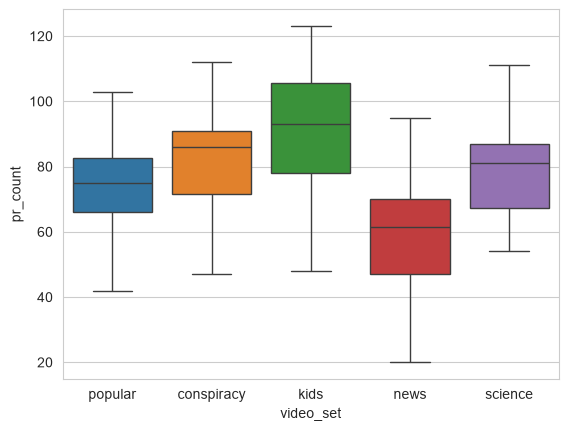

FriedmanchisquareResult(statistic=np.float64(68.47438330170789), pvalue=np.float64(1.3519996842214672e-15))
              tt            tf            ff
tt  1.000000e+00  1.110303e-15  1.354852e-12
tf  1.110303e-15  1.000000e+00  2.643616e-01
ff  1.354852e-12  2.643616e-01  1.000000e+00
          Source         W  ddof1          Q         p_unc
Friedman  Within  0.228248      2  68.474383  1.352000e-15


In [48]:
from dfply import *
from scipy import stats

BLOCK_VAR = "video_set" # 'video_set' or 'country'

print(dft >> group_by(X[BLOCK_VAR]) >> summarize(n=X[metric].count(),
                                           mean=X[metric].mean(), 
                                           median=X[metric].median(),
                                           std=X[metric].std()))

import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(data=iddf, x=BLOCK_VAR, y=metric, hue=iddf.video_set.tolist())
plt.show()

# Doing Friedman test with posthocs here. Only for nonnormal data

import pingouin as pg

#     data : Dataframe (wide or long format)
#     dv : Name of column in dataframe that contains dependent variable
#     within : Name of column in dataframe that contains within-subject factor (treatment)
#     subject : Name of column in dataframe that contains subjects (block)

#  Kendall’s W indicates effect size (degree of difference).
# Kendall’s W is based on Cohen’s interpretation guidelines (0.1: small effect; 0.3: moderate effect; and >0.5: large effect).

# friedman without blocks
fres = stats.friedmanchisquare(ttl, tfl, ffl)
print(fres)
friedman_stat = fres[0]

dataf = pd.DataFrame({
    "tt":ttl,
    "tf":tfl,
    "ff":ffl
})
posthoc_result = sp.posthoc_conover_friedman(dataf, p_adjust='holm')
print(posthoc_result)

# posthoc
# The FDR method will be used to adjust the p values for multiple hypothesis testing at a 5% cut-off
# different p_adjust: https://scikit-posthocs.readthedocs.io/en/latest/generated/scikit_posthocs.posthoc_conover_friedman.html
import scikit_posthocs as sp

# print(pg.friedman(data=iddf, dv=metric, within="privacy_code", subject="index", method='f'))
print(pg.friedman(dataf, method='chisq'))

# display(sp.posthoc_conover_friedman(a=iddf, y_col=metric, group_col="privacy_code", block_col=BLOCK_VAR, 
#                             p_adjust="holm", melted=True))

# display(sp.posthoc_nemenyi_friedman(a=iddf, y_col=metric, group_col="privacy_code", block_col=BLOCK_VAR, melted=True))


ShapiroResult(statistic=np.float64(0.8322697938843429), pvalue=np.float64(8.140936892077242e-12))
KstestResult(statistic=np.float64(0.4209001242260724), pvalue=np.float64(1.324435509838794e-24), statistic_location=np.float64(-0.1995912795726696), statistic_sign=np.int8(-1))
LeveneResult(statistic=np.float64(27.94277488816013), pvalue=np.float64(3.675995228334267e-12))
ShapiroResult(statistic=np.float64(0.7307417739159409), pvalue=np.float64(2.439433473660781e-26))
KstestResult(statistic=np.float64(0.5), pvalue=np.float64(1.4889957076607294e-104), statistic_location=np.float64(0.0), statistic_sign=np.int8(-1))
LeveneResult(statistic=np.float64(27.942774888160137), pvalue=np.float64(3.675995228334228e-12))


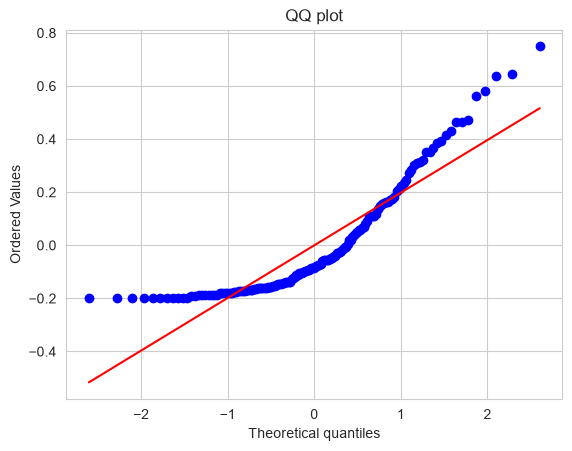

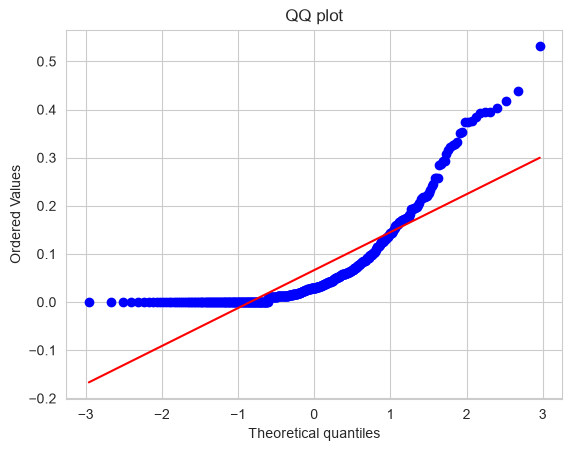

/var/folders/jm/1_69h8ts1hqb42r2llvj363c0000gn/T/ipykernel_81658/780383629.py:34: RuntimeWarning: divide by zero encountered in log
  stats.probplot(np.log(all_data), dist="norm", plot=plt)
/Users/catmai/jupyter-env/lib/python3.14/site-packages/scipy/stats/_stats_py.py:1172: RuntimeWarning: invalid value encountered in subtract
  a_zero_mean = a - mean


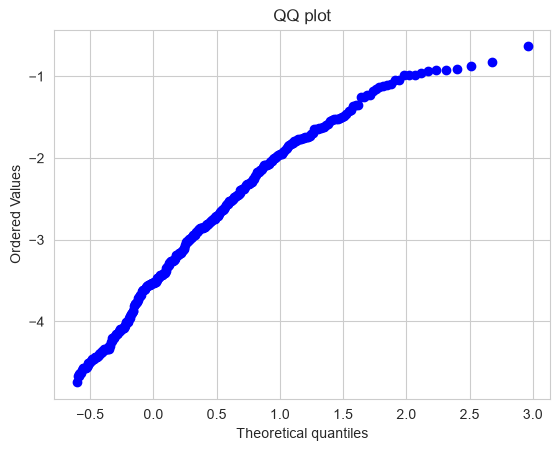

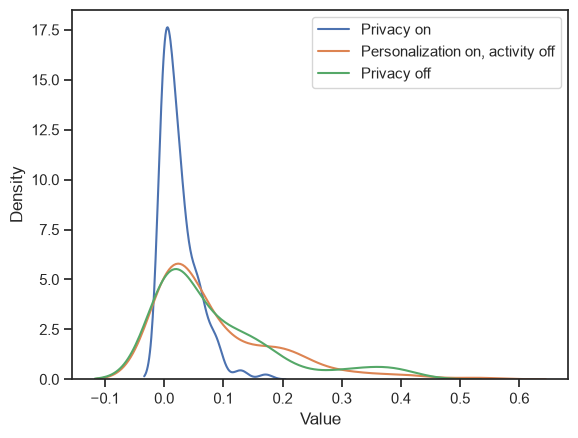

(array([73., 21., 16., 14.,  8.,  3.,  3.,  4.,  4.,  4.]),
 array([0.        , 0.04186047, 0.08372093, 0.1255814 , 0.16744186,
        0.20930233, 0.25116279, 0.29302326, 0.33488372, 0.37674419,
        0.41860465]),
 <BarContainer object of 10 artists>)

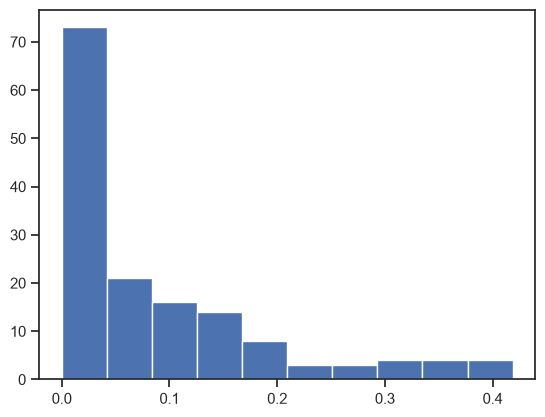

In [49]:
# Test for normality and equal variances (reject i.e. not normal when low p values)

# Normality: Since conspiracy alone n=27, use Shapiro-Wilk. Combining other video types, n > 50, use KS.
# Equal variances: use levene, already use variances of residuals
tt_resids = ttl - np.mean(ttl)
tf_resids = tfl - np.mean(tfl)
ff_resids = ffl - np.mean(ffl)

all_resids = tt_resids + tf_resids + ff_resids
all_data = ttl + tfl + ffl

# on residuals

print(shapiro(all_resids))
print(kstest(all_resids, 'norm'))
print(levene(tt_resids, tf_resids, ff_resids, center='median'))


# on actual data
print(shapiro(test["rate"]))
print(kstest(test["rate"], 'norm'))
print(levene(ttl, tfl, ffl, center='median'))

from scipy import stats

stats.probplot(all_resids, dist="norm", plot=plt)
plt.title("QQ plot")
plt.show()

stats.probplot(all_data, dist="norm", plot=plt)
plt.title("QQ plot")
plt.show()

stats.probplot(np.log(all_data), dist="norm", plot=plt)
plt.title("QQ plot")
plt.show()

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(style="ticks")


ax1 = sns.kdeplot(ttl,label='Privacy on')
ax2 = sns.kdeplot(tfl,label='Personalization on, activity off',
                      common_norm=True)
ax3 = sns.kdeplot(ffl,label='Privacy off',
                      common_norm=True)

plt.legend(loc="upper right")
plt.xlabel('Value')
plt.ylabel('Density')
plt.show()

plt.hist(ffl)

In [50]:
# Kruskal-Wallis and Dunn post-hoc
stat, p = kruskal(ttl, tfl, ffl)
print('Kruskal results:')
print(f"{p:.10f} or {p}")
print(f"{stat:.10f}")

# friedman without blocks
print(stats.friedmanchisquare(ttl, tfl, ffl))

data = [ttl, tfl, ffl]
dunn_results = posthoc_dunn(data, p_adjust='bonferroni')
print('Dunn results:')
display(dunn_results)
display(dunn_results < 0.01)

#quick dirty comparisons, not supposed to do 2 comparisons https://www.graphpad.com/guides/prism/latest/statistics/beware_of_multiple_comparisons.htm
print(stats.wilcoxon(ttl, tfl, zero_method='wilcox'))
print(stats.wilcoxon(ttl, ffl, zero_method='wilcox'))
print(stats.wilcoxon(tfl, ffl, zero_method='wilcox'))

Kruskal results:
0.0000000054 or 5.3795063470904086e-09
38.0813384481
FriedmanchisquareResult(statistic=np.float64(68.47438330170789), pvalue=np.float64(1.3519996842214672e-15))
Dunn results:


,1,2,3
1,1.000000e+00,1.088667e-07,7.258026e-07
2,1.088667e-07,1.000000e+00,1.000000e+00
3,7.258026e-07,1.000000e+00,1.000000e+00


,1,2,3
1,False,True,True
2,True,False,False
3,True,False,False


WilcoxonResult(statistic=np.float64(852.0), pvalue=np.float64(1.5397017740418243e-15))
WilcoxonResult(statistic=np.float64(647.0), pvalue=np.float64(1.3375050975721084e-15))
WilcoxonResult(statistic=np.float64(4520.0), pvalue=np.float64(0.9955701518473954))


In [52]:
# repeated measures one-way and two-way ANOVA
import pingouin as pg
dff = test

# repeated measures ANOVA (normality assumed)
subjects = list(range(1, len(ttl) + 1))

data = pd.DataFrame({
    'Subject': subjects * 3,  # Repeat the subjects for each condition
    'Condition': ['Privacy on'] * len(subjects) + 
                 ['Privacy off'] * len(subjects) + 
                 ['Personalization on, activity off'] * len(subjects),
    'Value': ttl + ffl + tfl
})

aovrm = AnovaRM(data, 'Value', 'Subject', within=['Condition'])
res = aovrm.fit()
print(res.summary())

# Sphericity (Mauchly’s Test), if violated, use Greenhouse-Geisser correction
# print(pg.sphericity(data, dv='Value', within='Condition', subject='Subject'))

# # one-way repeated measures ANOVA
anova_oneway = pg.rm_anova(dv='Value', within='Condition', subject='Subject', data=data, detailed=True)
print(anova_oneway)

# two-way repeated measures ANOVA
# anova_twoway = pg.rm_anova(dv=metric, within=['privacy_code', BLOCK_VAR], subject='location', data=iddf, detailed=True)
# print(anova_twoway)

pairwise = pg.pairwise_tests(dv='Value', within='Condition', subject='Subject', data=data, padjust='bonferroni')
print(pairwise)


                 Anova
          F Value Num DF  Den DF  Pr > F
----------------------------------------
Condition 51.1361 2.0000 298.0000 0.0000

      Source        SS   DF        MS          F         p_unc     p_GG_corr  \
0  Condition  0.382392    2  0.191196  51.136094  8.077304e-20  3.952201e-18   
1      Error  1.114212  298  0.003739        NaN           NaN           NaN   

        ng2       eps sphericity  W_spher   p_spher  
0  0.100974  0.902104      False  0.89148  0.000203  
1       NaN       NaN        NaN      NaN       NaN  
    Contrast                                 A            B  Paired  \
0  Condition  Personalization on, activity off  Privacy off    True   
1  Condition  Personalization on, activity off   Privacy on    True   
2  Condition                       Privacy off   Privacy on    True   

   Parametric         T    dof alternative         p_unc        p_corr  \
0        True -0.164308  149.0   two-sided  8.697111e-01  1.000000e+00   
1        True  8.

In [53]:
# one-way anova (for normal things, which are pr_count and ad_count

f_statistic, p_value = stats.f_oneway(ttl, tfl, ffl)
print(f"F-Statistic: {f_statistic:.9f}")
print(f"P-Value: {p_value}")

model = ols('Value ~ C(Condition)', data=data).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

# post hoc
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(data['Value'], data['Condition'], alpha=0.0001)
print(tukey)

F-Statistic: 25.102474199
P-Value: 4.656504972796786e-11
                sum_sq     df          F        PR(>F)
C(Condition)  0.382392    2.0  25.102474  4.656505e-11
Residual      3.404632  447.0        NaN           NaN
                Multiple Comparison of Means - Tukey HSD, FWER=0.00                
             group1                 group2   meandiff p-adj   lower   upper  reject
-----------------------------------------------------------------------------------
Personalization on, activity off Privacy off    0.001 0.9951 -0.0413  0.0432  False
Personalization on, activity off  Privacy on  -0.0614    0.0 -0.1036 -0.0191   True
                     Privacy off  Privacy on  -0.0623    0.0 -0.1045 -0.0201   True
-----------------------------------------------------------------------------------


In [60]:
def output_glm(df):
    ff_str = "C(privacy_code, Treatment(reference='True_True'))[T.False_False]"
    tf_str = "C(privacy_code, Treatment(reference='True_True'))[T.True_False]"
    ffdf = df.loc[ff_str]
    tfdf = df.loc[tf_str]
    
    tf_rate = tfdf['coeff_rate']
    tf_ci = f"[{tfdf['95ci_lower']:.2f}, {tfdf['95ci_higher']:.2f}]"
    tf_punc = tfdf['P>|z|']
    
    ff_rate = ffdf['coeff_rate']
    ff_ci = f"[{ffdf['95ci_lower']:.2f}, {ffdf['95ci_higher']:.2f}]"
    ff_punc = ffdf['P>|z|']
    
    n = df.iloc[0]['n']
    prs = df.iloc[0]['prs']
    
    comment = f"% p-unc (tf/ff): {tf_punc}, {ff_punc}"
    out = f"{tf_rate:.2f} & {tf_ci} & {ff_rate:.2f} & {ff_ci} & {prs} & {int(n)} \\\\ {comment}"
    
    print(out)
    
def exp(num):
    try:
        result = math.exp(num)
    except OverflowError:
        result = float('inf')
    return result

import io

def glm_summary_to_df(results, sigfig=3):
    # Wrap tables[1] HTML in io.StringIO
    results_as_html = results.summary().tables[1].as_html()
    dff = pd.read_html(io.StringIO(results_as_html), header=0, index_col=0)[0]
    
    dff['coeff_rate'] = dff['coef'].apply(lambda x: exp(x)).round(sigfig)   
    dff['95ci_lower'] = dff["[0.025"].apply(lambda x: exp(x)).round(sigfig)
    dff['95ci_higher'] = dff["0.975]"].apply(lambda x: exp(x)).round(sigfig)
    
    # Wrap tables[0] HTML in io.StringIO as well
    results_as_html_0 = results.summary().tables[0].as_html()
    model_summary = pd.read_html(io.StringIO(results_as_html_0))[0]
    
    ncount = int(model_summary.iloc[0][3]/3)
    prs = model_summary.iloc[7][3].round(2)
    
    dff['n'] = [ncount]*len(dff)
    dff['prs'] = [prs]*len(dff)
    return dff

In [61]:
# poisson
import statsmodels.api as sm
import statsmodels.formula.api as smf

dft = iddf
# dft = gbr

metric = "pr_count"


dff = dft

# robust covariance, similar to quasipoisson
poisson_model = smf.glm(
    formula=f"{metric} ~ C(country)+C(privacy_code, Treatment(reference='True_True')) + C(video_set)",
    data=dff,
    family=sm.families.Poisson(),
    
#     offset=np.log(dff['pr_count']) #offset only for scam count
).fit() #cov_type="HC3"
print(poisson_model.pseudo_rsquared(kind='mcf'))
print(poisson_model.summary())
res = glm_summary_to_df(poisson_model, sigfig=2)
display(res)
output_glm(res)

dff['predicted'] = poisson_model.predict(dff)
dff['residuals'] = dff[metric] - dff['predicted']
dispersion_ratio = dff['residuals'].var() / dff['predicted'].mean()
print(f"Dispersion ratio: {dispersion_ratio}")
if dispersion_ratio > 1.5:
    print("overdispersion of data. use negative binom")

0.2897591693710754
                 Generalized Linear Model Regression Results                  
Dep. Variable:               pr_count   No. Observations:                  450
Model:                            GLM   Df Residuals:                      439
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1713.9
Date:                Wed, 11 Nov 2026   Deviance:                       660.41
Time:                        17:36:25   Pearson chi2:                     625.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.9553
Covariance Type:            nonrobust                                         
                                                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------

,coef,std err,z,P>|z|,[0.025,0.975],coeff_rate,95ci_lower,95ci_higher,n,prs
Intercept,4.2699,0.018,238.678,0.000,4.235,4.305,71.51,69.06,74.07,150,0.96
C(country)[T.can],-0.0594,0.017,-3.489,0.000,-0.093,-0.026,0.94,0.91,0.97,150,0.96
C(country)[T.gbr],0.0027,0.017,0.159,0.873,-0.030,0.036,1.00,0.97,1.04,150,0.96
C(country)[T.irl],-0.1573,0.017,-9.005,0.000,-0.192,-0.123,0.85,0.83,0.88,150,0.96
C(country)[T.usa],0.0676,0.016,4.096,0.000,0.035,0.100,1.07,1.04,1.11,150,0.96
"C(privacy_code, Treatment(reference='True_True'))[T.False_False]",0.2599,0.014,19.212,0.000,0.233,0.286,1.30,1.26,1.33,150,0.96
"C(privacy_code, Treatment(reference='True_True'))[T.True_False]",0.2457,0.014,18.112,0.000,0.219,0.272,1.28,1.24,1.31,150,0.96
C(video_set)[T.kids],0.0962,0.016,6.016,0.000,0.065,0.127,1.10,1.07,1.14,150,0.96
C(video_set)[T.news],-0.3567,0.018,-19.781,0.000,-0.392,-0.321,0.70,0.68,0.73,150,0.96
C(video_set)[T.popular],-0.1217,0.017,-7.208,0.000,-0.155,-0.089,0.89,0.86,0.91,150,0.96


1.28 & [1.24, 1.31] & 1.30 & [1.26, 1.33] & 0.96 & 150 \\ % p-unc (tf/ff): 0.0, 0.0
Dispersion ratio: 1.2526255790961163


In [62]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

dft = iddf
# dft = gbr

metric = "pr_scam_count"

# Negative binomial probability models arise from a Poisson-Gamma mixture.
# That is, there is an unknown fluctuating Gamma random variable "feeding into" the Poisson rate parameter.
# Since NB GLM fitting is likelihood based, it is usually helpful to state prior beliefs about the data generating mechanism 
# and connect them to the probabilistic rationale for the model at hand.
# https://stats.stackexchange.com/questions/201903/how-to-deal-with-overdispersion-in-poisson-regression-quasi-likelihood-negativ

test['privacy'] = test['privacy'].astype('category')
test['privacy_code'] = test['privacy'].cat.codes

nb_glm = smf.glm(data=dft,       
                formula=f"{metric} ~ C(country)+ C(video_set)+C(privacy_code, Treatment(reference='True_True'))",
                family=sm.families.NegativeBinomial(),
                offset=np.log(dft['pr_count']))
nb_results = nb_glm.fit()

print(nb_results.summary())
res = glm_summary_to_df(nb_results, sigfig=2)
display(res)
output_glm(res)


                 Generalized Linear Model Regression Results                  
Dep. Variable:          pr_scam_count   No. Observations:                  450
Model:                            GLM   Df Residuals:                      439
Model Family:        NegativeBinomial   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1041.3
Date:                Wed, 11 Nov 2026   Deviance:                       387.66
Time:                        17:36:28   Pearson chi2:                     386.
No. Iterations:                    10   Pseudo R-squ. (CS):             0.5549
Covariance Type:            nonrobust                                         
                                                                       coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------

/var/folders/jm/1_69h8ts1hqb42r2llvj363c0000gn/T/ipykernel_81658/2542462207.py:20: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


,coef,std err,z,P>|z|,[0.025,0.975],coeff_rate,95ci_lower,95ci_higher,n,prs
Intercept,-2.6381,0.181,-14.543,0.000,-2.994,-2.283,0.07,0.05,0.10,150,0.55
C(country)[T.can],0.1349,0.178,0.760,0.447,-0.213,0.483,1.14,0.81,1.62,150,0.55
C(country)[T.gbr],-0.0913,0.179,-0.509,0.611,-0.443,0.260,0.91,0.64,1.30,150,0.55
C(country)[T.irl],0.2268,0.178,1.275,0.202,-0.122,0.575,1.25,0.89,1.78,150,0.55
C(country)[T.usa],0.1397,0.176,0.793,0.428,-0.206,0.485,1.15,0.81,1.62,150,0.55
C(video_set)[T.kids],-2.5103,0.183,-13.746,0.000,-2.868,-2.152,0.08,0.06,0.12,150,0.55
C(video_set)[T.news],-0.6443,0.162,-3.986,0.000,-0.961,-0.328,0.53,0.38,0.72,150,0.55
C(video_set)[T.popular],-2.0363,0.177,-11.522,0.000,-2.383,-1.690,0.13,0.09,0.18,150,0.55
C(video_set)[T.science],-1.5123,0.167,-9.055,0.000,-1.840,-1.185,0.22,0.16,0.31,150,0.55
"C(privacy_code, Treatment(reference='True_True'))[T.False_False]",0.9901,0.144,6.864,0.000,0.707,1.273,2.69,2.03,3.57,150,0.55


2.87 & [2.17, 3.81] & 2.69 & [2.03, 3.57] & 0.55 & 150 \\ % p-unc (tf/ff): 0.0, 0.0
